# EDA: ceny mieszkań i kontekst makro
Cel: ocenić jakość, zakres oraz zależności publicznych danych przed prognozą miejskich średnich cen. Nie analizujemy statusów rezerwacji deweloperów.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
assert (ROOT/'config/config.yaml').exists(),'Uruchom z folderu projektu lub notebooks'
if str(ROOT)not in sys.path:sys.path.insert(0,str(ROOT))
import pandas as pd,numpy as np
from IPython.display import display,Image
from src.common import FEATURES,TARGETS


In [2]:
audit=json.loads((ROOT/'reports/tables/source_audit.json').read_text());display(audit)
prices=pd.read_csv(ROOT/'data/processed/prices_long.csv');display(prices.groupby(['market','series_type']).agg(n=('value','size'),min_quarter=('quarter','min'),max_quarter=('quarter','max')))

{'raw_provider_observations': 9337,
 'price_min_quarter': '2006Q3',
 'price_max_quarter': '2026Q2',
 'duplicate_keys': 0,
 'nonpositive_prices': 0,
 'mortgage_count_quarters': 71,
 'macro_missing': {'policy_rate': 0,
  'cpi': 0,
  'inflation': 4,
  'policy_change': 4,
  'wage': 29,
  'wage_yoy': 33,
  'sloos_easing': 43,
  'sloos_demand': 43,
  'mortgage_rate': 88,
  'mortgage_flow': 88,
  'real_flow_yoy': 92}}

n min_quarter max_quarter
market    series_type                              
primary   offer        1597      2006Q3      2026Q2
          transaction  1599      2006Q3      2026Q2
secondary hedonic_qoq  1499      2006Q3      2026Q2
          hedonic_yoy  1442      2007Q2      2026Q2
          offer        1600      2006Q3      2026Q2
          transaction  1600      2006Q3      2026Q2

Ceny transakcyjne są etykietą. Ceny ofertowe służą wyłącznie opisowi. Indeks hedoniczny ma inną jednostkę niż PLN/m²; nie mieszamy ich w jednej kolumnie celu.

In [3]:
display(prices.head());display(prices.groupby('series_type').value.describe());print('Duplikaty klucza:',prices.duplicated(['quarter','area','market','series_type']).sum())

,quarter,area,area_clean,market,series_type,value,series_id,is_aggregate,sheet,row_excel,column_excel
0,2006Q3,Białystok,Białystok,primary,transaction,3008.0,primary_avg_bialystok,False,Rynek pierwotny,8,25
1,2006Q4,Białystok,Białystok,primary,transaction,3117.0,primary_avg_bialystok,False,Rynek pierwotny,9,25
2,2007Q1,Białystok,Białystok,primary,transaction,3500.0,primary_avg_bialystok,False,Rynek pierwotny,10,25
3,2007Q2,Białystok,Białystok,primary,transaction,4422.0,primary_avg_bialystok,False,Rynek pierwotny,11,25
4,2007Q3,Białystok,Białystok,primary,transaction,4651.0,primary_avg_bialystok,False,Rynek pierwotny,12,25


,count,mean,std,min,25%,50%,75%,max
series_type,,,,,,,,
hedonic_qoq,1499.0,101.584010,4.871346,78.620463,99.216582,101.099542,103.332695,148.653924
hedonic_yoy,1442.0,105.706152,10.646123,79.803927,99.719184,104.016021,110.512536,209.974967
offer,3197.0,7077.636131,2916.491366,2136.754149,4906.825631,6337.747036,8551.210177,19093.825136
transaction,3199.0,6459.170835,2682.027446,1871.967387,4590.732711,5732.083530,7744.085423,16972.408509


Duplikaty klucza: 0


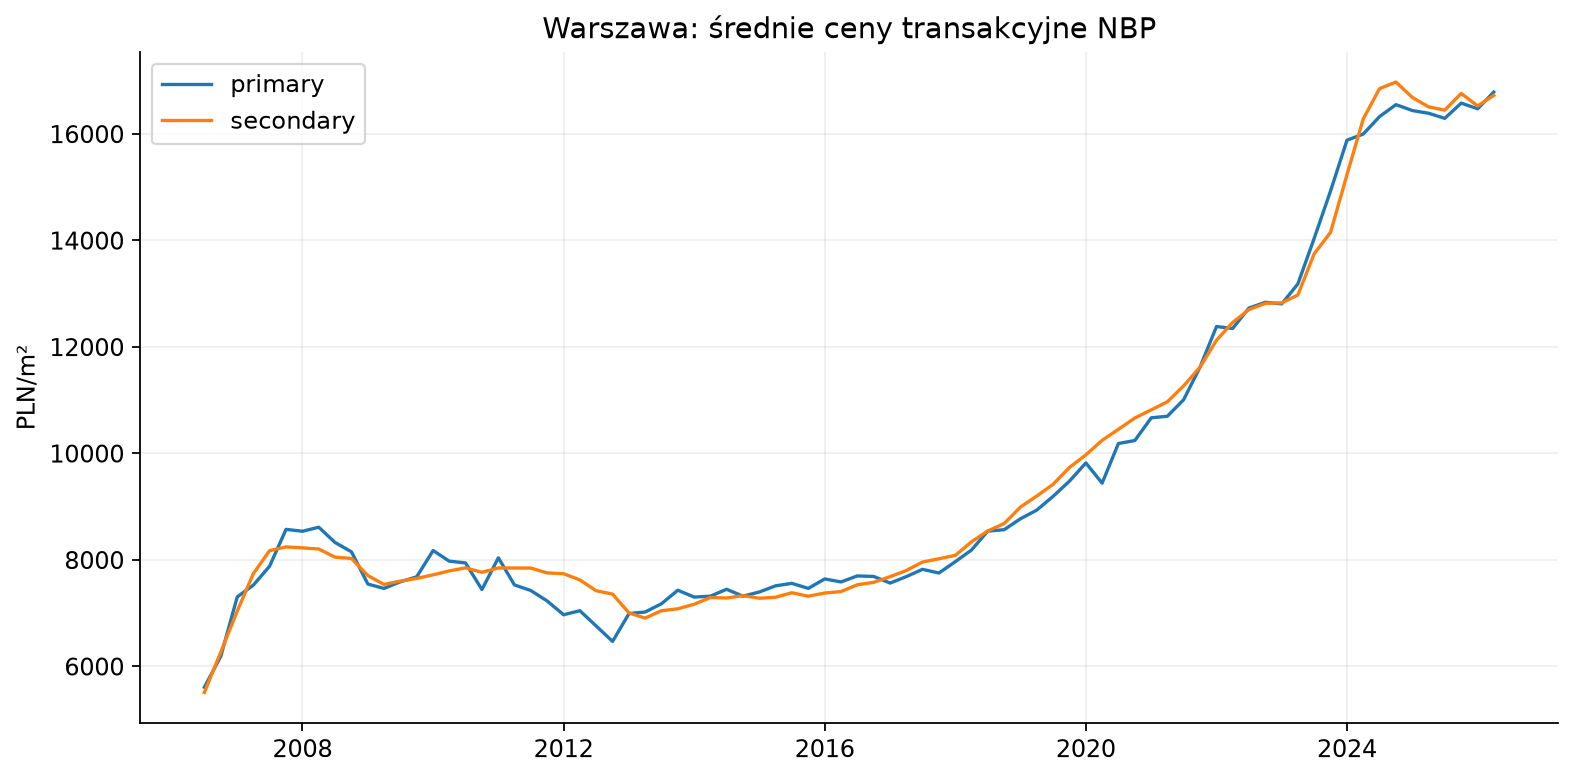

In [4]:
display(Image(filename=str(ROOT/'reports/figures/01_prices.png')))

Trend poziomu ceny nie jest stacjonarny. Wspólny kierunek miast nie dowodzi przyczynowości inflacji lub dopłat. Średnia zmienia się także wraz ze strukturą sprzedanych lokali.

In [5]:
f=pd.read_csv(ROOT/'data/processed/training_wide.csv');display(f[FEATURES].describe().T);display(f[FEATURES].isna().mean().sort_values(ascending=False).to_frame('missing_fraction'))

,count,mean,std,min,25%,50%,75%,max
local_yoy_known2,2379.0,6.565097,12.077727,-25.412642,-0.204913,4.877540,10.974063,112.936463
local_qoq_known2,2379.0,1.201660,4.116647,-25.086024,-0.891274,0.978966,3.115591,57.932596
local_yoy_acceleration_known2,2243.0,-1.474093,13.698575,-118.285925,-4.833641,0.676422,5.542016,35.178669
local_volatility4_known2,2379.0,3.418132,3.298601,0.133476,1.602517,2.535301,4.070659,48.793317
relative_price_known2,2379.0,1.082051,0.237174,0.661352,0.917066,1.000000,1.239838,1.884606
primary_secondary_ratio_known2,2238.0,1.151615,0.131948,0.727515,1.053494,1.145760,1.230705,1.705538
peer_yoy_known2,2379.0,6.565097,10.591928,-9.193385,0.732156,3.823379,10.856986,66.166051
log_known_price,2379.0,8.659747,0.338206,7.957376,8.419989,8.607399,8.892588,9.739344
policy_rate_lag1,2379.0,3.175242,1.979229,0.100000,1.500000,2.750000,4.750000,6.750000
policy_rate_change4q_lag1,2379.0,0.081547,1.638571,-2.500000,-0.900000,0.000000,0.250000,6.650000


,missing_fraction
hedonic_yoy_known,0.559899
hedonic_qoq_known,0.558638
national_real_credit_flow_yoy_lag1,0.471206
national_mortgage_rate_lag1,0.414040
credit_count_acceleration_lag2,0.185372
credit_count_t4_yoy_lag2,0.171080
credit_count_yoy_lag2,0.128205
credit_count_qoq_lag2,0.085330
primary_secondary_ratio_known2,0.059269
local_yoy_acceleration_known2,0.057167


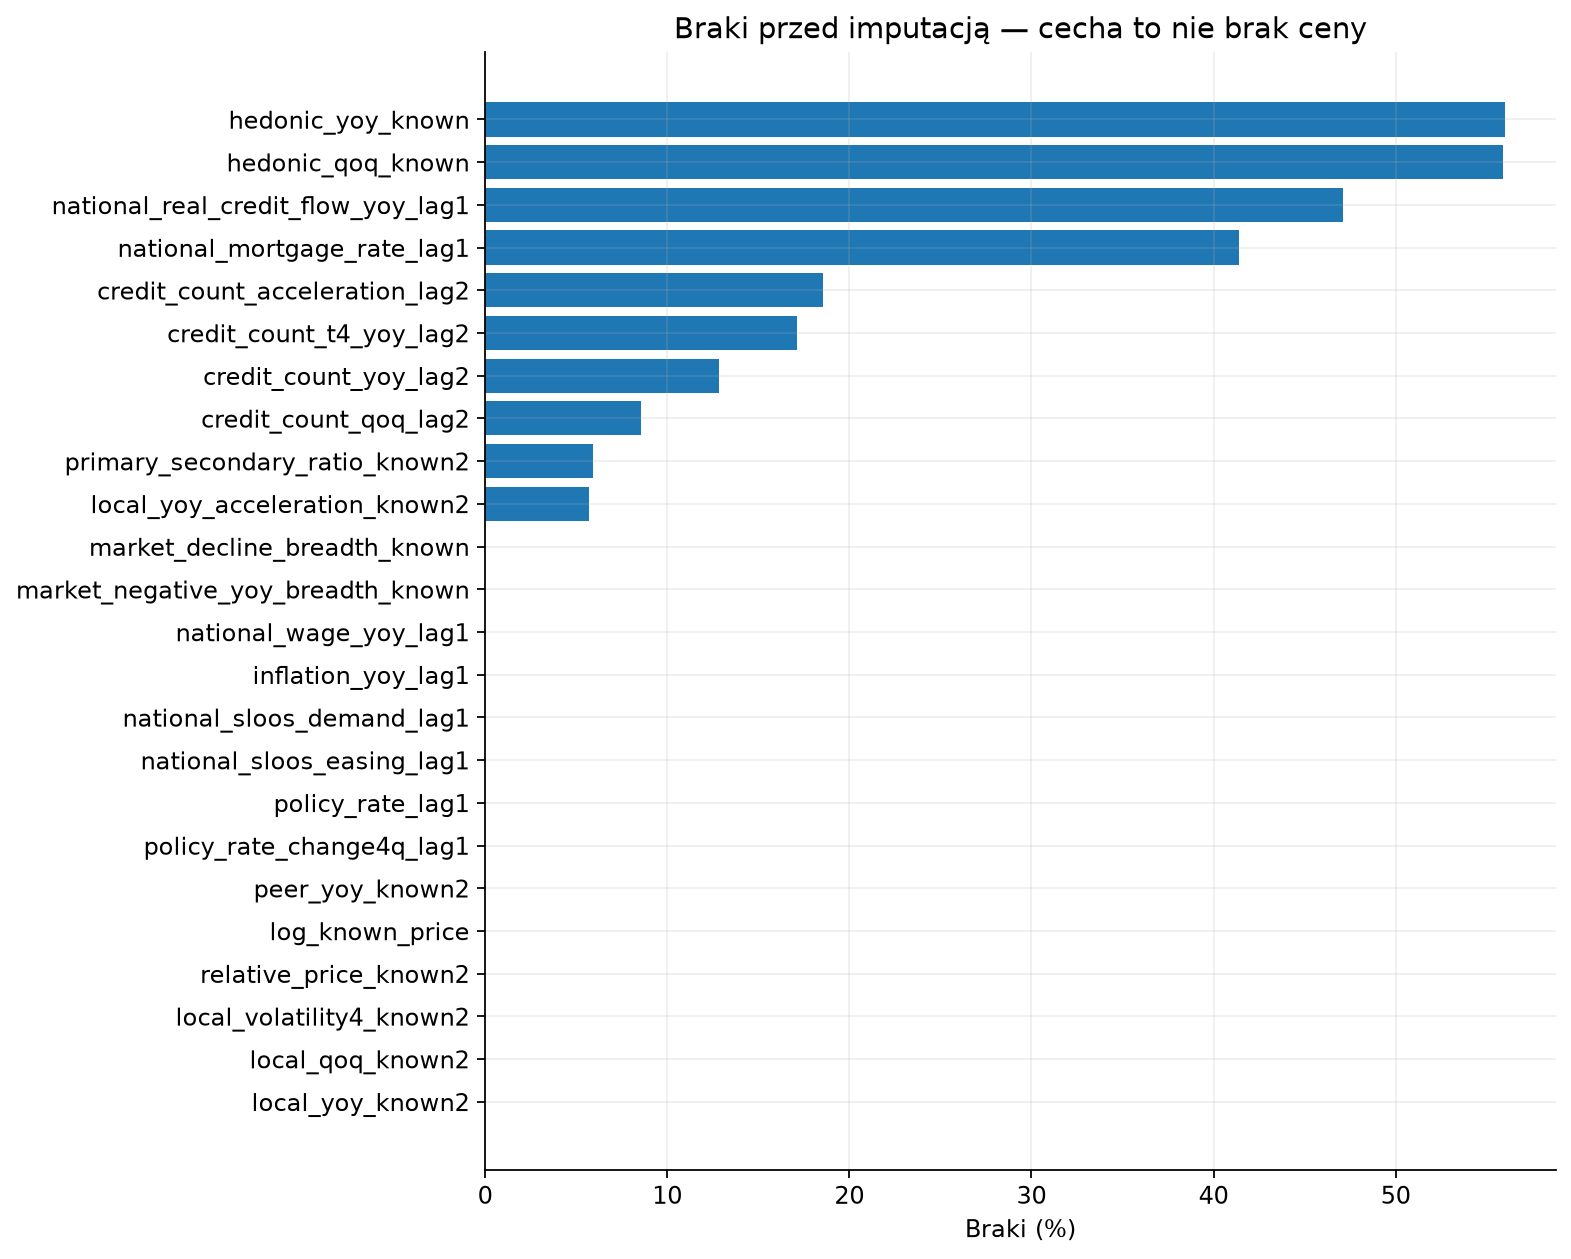

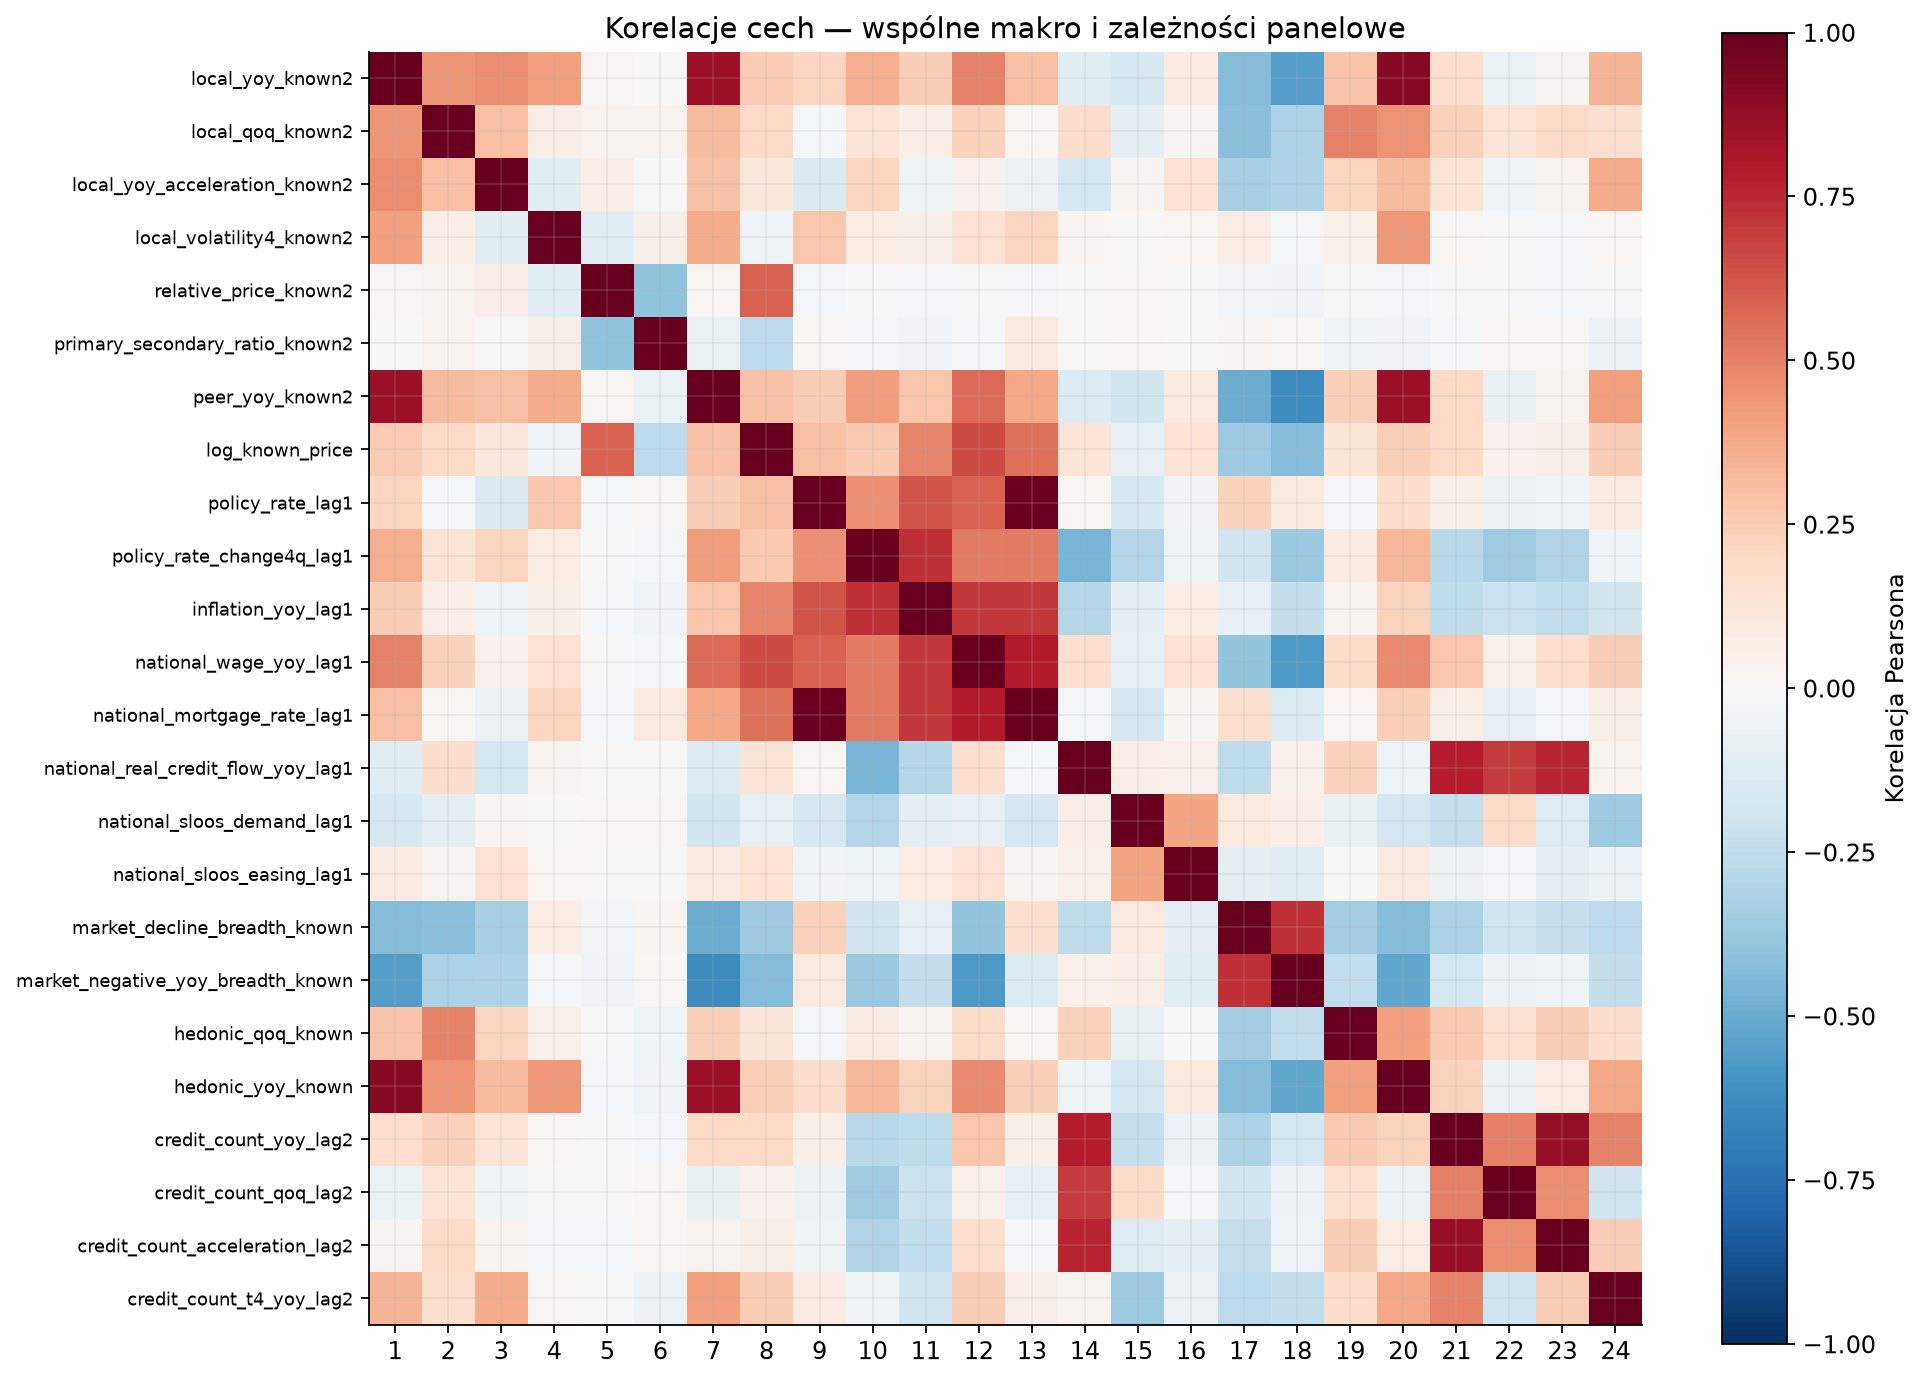

In [6]:
display(Image(filename=str(ROOT/'reports/figures/02_missing.png')));display(Image(filename=str(ROOT/'reports/figures/03_correlations.png')))

Braki indeksów dla rynku pierwotnego i wcześniejszego kredytu są strukturalne. Nie uzupełniamy ich z przyszłości. Nie usuwamy automatycznie skrajnych cen: mogą reprezentować zmianę cyklu. Wysokie korelacje i wspólne makro oznaczają mniejszą niezależność obserwacji niż sama liczba wierszy.

In [7]:
display(json.loads((ROOT/'reports/tables/dataset_audit.json').read_text()))

{'long_rows': 11895,
 'independent_city_origin_groups': 2379,
 'unique_origins': 70,
 'numeric_features': 24,
 'categorical_features': 2,
 'series': 34,
 'cities': 17,
 'min_origin': '2008Q1',
 'max_origin': '2025Q2',
 'reference_origin': '2026Q3',
 'test_origin': '2025Q2',
 'raw_price_observations': 9337,
 'warning': 'Five horizons share one origin vector; long rows are not independent markets or cycles.'}

Wniosek EDA:11895etykiet horyzontów współdzieli2379wektorów. To wystarcza do demonstracji panelowego forecastingu, ale nie dostarcza tysięcy niezależnych załamań rynku. Nie imputujemy ceny docelowej ani nie interpolujemy brakujących etykiet.